In [9]:
!pip install -q kagglehub torchvision torchinfo
import kagglehub
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.utils import make_grid
from PIL import Image
import os
import glob
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [10]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
train_dir = os.path.join(path, 'chest_xray', 'train')
print("Training directory target:", train_dir)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Training directory target: /kaggle/input/chest-xray-pneumonia/chest_xray/train


In [11]:
class GrayscaleStreamingXRayDataset(Dataset):
    """
    Streams chest X-ray images lazily from disk in single-channel grayscale.
    """
    def __init__(self, root_dir, transform=None):
        self.image_paths = []
        for ext in ('*.jpeg', '*.jpg', '*.png'):
            self.image_paths.extend(glob.glob(os.path.join(root_dir, '**', ext), recursive=True))
        self.transform = transform
        print(f"Found {len(self.image_paths)} grayscale images ready for streaming.")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        # Open strictly as grayscale ('L' mode)
        image = Image.open(img_path).convert('L')
        if self.transform:
            image = self.transform(image)
        return image

# Resize to 128x128, convert to tensor, and normalize to [-1, 1]
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.CenterCrop(128),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

batch_size = 64
dataset = GrayscaleStreamingXRayDataset(train_dir, transform=transform)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)

Found 5216 grayscale images ready for streaming.


In [12]:
class PretrainedFeatureExtractor(nn.Module):
    """
    Frozen ResNet-18 feature extractor. Automatically expands 1-channel grayscale
    images to 3 channels to match pre-trained weights.
    """
    def __init__(self):
        super(PretrainedFeatureExtractor, self).__init__()
        resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.feature_extractor = nn.Sequential(*list(resnet.children())[:-2])
        for param in self.feature_extractor.parameters():
            param.requires_grad = False

    def forward(self, x):
        # Expand grayscale (Batch, 1, 128, 128) to 3 channels for ResNet-18
        if x.size(1) == 1:
            x = x.repeat(1, 3, 1, 1)
        return self.feature_extractor(x)

class Generator(nn.Module):
    def __init__(self, latent_dim=100):
        super(Generator, self).__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),

            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 32, 4, 2, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(True),

            # Output 1 channel for grayscale X-ray
            nn.ConvTranspose2d(32, 1, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)

class Critic(nn.Module):
    """
    WGAN Critic (replaces traditional Discriminator). Outputs an unconstrained
    scalar score instead of a probability, avoiding gradient saturation.
    """
    def __init__(self):
        super(Critic, self).__init__()
        self.net = nn.Sequential(
            # Input: (1, 128, 128)
            nn.Conv2d(1, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.InstanceNorm2d(128), # InstanceNorm is preferred over BatchNorm in WGAN-GP
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.InstanceNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.InstanceNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Conv2d(512, 1, 1, 1, 0, bias=False)
            # NOTE: No Sigmoid activation here!
        )

    def forward(self, img):
        return self.net(img).view(-1, 1)

In [13]:
latent_dim = 100
# TTUR (Two-Time-Scale Update Rule): slightly higher learning rate for G, standard WGAN-GP betas
lr_g = 0.0002
lr_d = 0.0001
beta1 = 0.0
beta2 = 0.9
n_critic = 5 # Train critic 5 times per 1 generator update for stability

netG = Generator(latent_dim).to(device)
netC = Critic().to(device)
feature_extractor = PretrainedFeatureExtractor().to(device)
feature_extractor.eval()

optimizerG = optim.Adam(netG.parameters(), lr=lr_g, betas=(beta1, beta2))
optimizerC = optim.Adam(netC.parameters(), lr=lr_d, betas=(beta1, beta2))

def compute_gradient_penalty(critic, real_samples, fake_samples, device):
    """Calculates the gradient penalty loss for WGAN-GP."""
    alpha = torch.rand(real_samples.size(0), 1, 1, 1, device=device)
    interpolates = (alpha * real_samples + ((1 - alpha) * fake_samples)).requires_grad_(True)
    d_interpolates = critic(interpolates)

    fake = torch.ones(real_samples.size(0), 1, device=device, requires_grad=False)
    gradients = torch.autograd.grad(
        outputs=d_interpolates,
        inputs=interpolates,
        grad_outputs=fake,
        create_graph=True,
        retain_graph=True,
        only_inputs=True,
    )[0]

    gradients = gradients.view(gradients.size(0), -1)
    gradient_penalty = ((gradients.norm(2, dim=1) - 1) ** 2).mean()
    return gradient_penalty

print("WGAN-GP Framework Initialized Successfully.")

WGAN-GP Framework Initialized Successfully.


Starting WGAN-GP training for 75 epochs...
Epoch [1/75] Batch [0/82] Loss Critic: 8.0079 | Loss G (Adv): 0.2747 | Loss G (Feat): 1.1056
Epoch [2/75] Batch [0/82] Loss Critic: -3.5060 | Loss G (Adv): 1.4923 | Loss G (Feat): 1.1014
Epoch [3/75] Batch [0/82] Loss Critic: -6.0019 | Loss G (Adv): 1.6876 | Loss G (Feat): 1.0200
Epoch [4/75] Batch [0/82] Loss Critic: -8.1864 | Loss G (Adv): 2.8325 | Loss G (Feat): 1.0504
Epoch [5/75] Batch [0/82] Loss Critic: -8.5075 | Loss G (Adv): 4.3299 | Loss G (Feat): 0.9797
Epoch [6/75] Batch [0/82] Loss Critic: -7.5386 | Loss G (Adv): 5.9009 | Loss G (Feat): 1.0092
Epoch [7/75] Batch [0/82] Loss Critic: -6.3508 | Loss G (Adv): 3.2859 | Loss G (Feat): 0.9757
Epoch [8/75] Batch [0/82] Loss Critic: -6.3483 | Loss G (Adv): 3.8587 | Loss G (Feat): 0.9171
Epoch [9/75] Batch [0/82] Loss Critic: -5.8652 | Loss G (Adv): 4.3924 | Loss G (Feat): 0.9481
Epoch [10/75] Batch [0/82] Loss Critic: -6.3103 | Loss G (Adv): 0.3781 | Loss G (Feat): 0.9082
Epoch [11/75] Bat

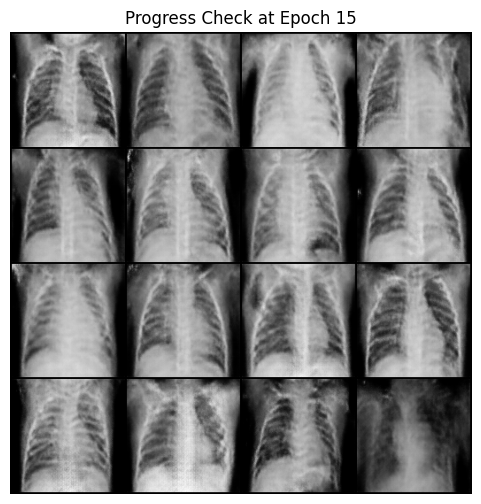

Epoch [16/75] Batch [0/82] Loss Critic: -5.2584 | Loss G (Adv): -0.0057 | Loss G (Feat): 0.8567
Epoch [17/75] Batch [0/82] Loss Critic: -5.0222 | Loss G (Adv): -0.5026 | Loss G (Feat): 0.8869
Epoch [18/75] Batch [0/82] Loss Critic: -5.6594 | Loss G (Adv): 0.4833 | Loss G (Feat): 0.8770
Epoch [19/75] Batch [0/82] Loss Critic: -5.1666 | Loss G (Adv): 1.0470 | Loss G (Feat): 0.8533
Epoch [20/75] Batch [0/82] Loss Critic: -5.5148 | Loss G (Adv): 1.1026 | Loss G (Feat): 0.8850
Epoch [21/75] Batch [0/82] Loss Critic: -5.4207 | Loss G (Adv): 1.6216 | Loss G (Feat): 0.8568
Epoch [22/75] Batch [0/82] Loss Critic: -5.4828 | Loss G (Adv): 1.5188 | Loss G (Feat): 0.8678
Epoch [23/75] Batch [0/82] Loss Critic: -4.2864 | Loss G (Adv): 2.3822 | Loss G (Feat): 0.8462
Epoch [24/75] Batch [0/82] Loss Critic: -5.2870 | Loss G (Adv): 1.1275 | Loss G (Feat): 0.8343
Epoch [25/75] Batch [0/82] Loss Critic: -4.9410 | Loss G (Adv): 5.7604 | Loss G (Feat): 0.8531
Epoch [26/75] Batch [0/82] Loss Critic: -5.2252 

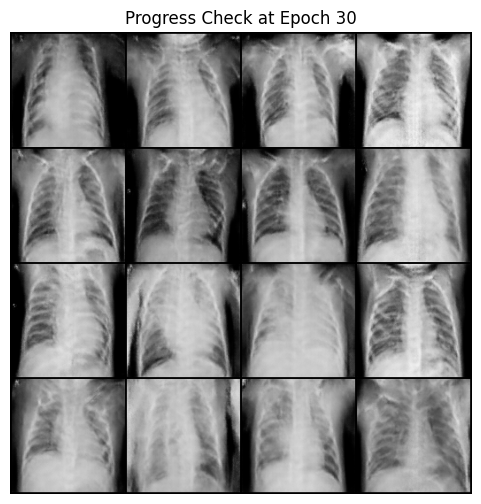

Epoch [31/75] Batch [0/82] Loss Critic: -4.6391 | Loss G (Adv): 10.0314 | Loss G (Feat): 0.8301
Epoch [32/75] Batch [0/82] Loss Critic: -4.6763 | Loss G (Adv): 10.6080 | Loss G (Feat): 0.8387
Epoch [33/75] Batch [0/82] Loss Critic: -4.4968 | Loss G (Adv): 14.1264 | Loss G (Feat): 0.8241
Epoch [34/75] Batch [0/82] Loss Critic: -4.6816 | Loss G (Adv): 14.7999 | Loss G (Feat): 0.8277
Epoch [35/75] Batch [0/82] Loss Critic: -4.5285 | Loss G (Adv): 15.3043 | Loss G (Feat): 0.8459
Epoch [36/75] Batch [0/82] Loss Critic: -4.2336 | Loss G (Adv): 17.0924 | Loss G (Feat): 0.7846
Epoch [37/75] Batch [0/82] Loss Critic: -4.2813 | Loss G (Adv): 18.3697 | Loss G (Feat): 0.8075
Epoch [38/75] Batch [0/82] Loss Critic: -4.6562 | Loss G (Adv): 20.8071 | Loss G (Feat): 0.8339
Epoch [39/75] Batch [0/82] Loss Critic: -4.6358 | Loss G (Adv): 21.9197 | Loss G (Feat): 0.8280
Epoch [40/75] Batch [0/82] Loss Critic: -4.5127 | Loss G (Adv): 22.5928 | Loss G (Feat): 0.8034
Epoch [41/75] Batch [0/82] Loss Critic: 

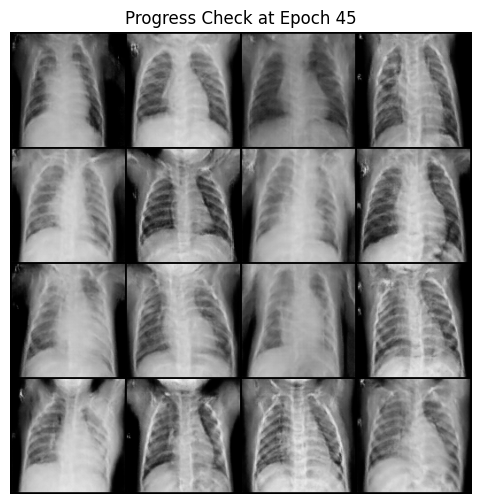

Epoch [46/75] Batch [0/82] Loss Critic: -4.0639 | Loss G (Adv): 33.4364 | Loss G (Feat): 0.8125
Epoch [47/75] Batch [0/82] Loss Critic: -4.0071 | Loss G (Adv): 36.0143 | Loss G (Feat): 0.8225
Epoch [48/75] Batch [0/82] Loss Critic: -4.5447 | Loss G (Adv): 37.0946 | Loss G (Feat): 0.8328
Epoch [49/75] Batch [0/82] Loss Critic: -3.8388 | Loss G (Adv): 38.1590 | Loss G (Feat): 0.8075
Epoch [50/75] Batch [0/82] Loss Critic: -4.5424 | Loss G (Adv): 42.4209 | Loss G (Feat): 0.8027
Epoch [51/75] Batch [0/82] Loss Critic: -4.2838 | Loss G (Adv): 40.8371 | Loss G (Feat): 0.7937
Epoch [52/75] Batch [0/82] Loss Critic: -4.0570 | Loss G (Adv): 43.4756 | Loss G (Feat): 0.7828
Epoch [53/75] Batch [0/82] Loss Critic: -5.1797 | Loss G (Adv): 44.3464 | Loss G (Feat): 0.7998
Epoch [54/75] Batch [0/82] Loss Critic: -4.1751 | Loss G (Adv): 46.3881 | Loss G (Feat): 0.7968
Epoch [55/75] Batch [0/82] Loss Critic: -4.4095 | Loss G (Adv): 47.3447 | Loss G (Feat): 0.8038
Epoch [56/75] Batch [0/82] Loss Critic: 

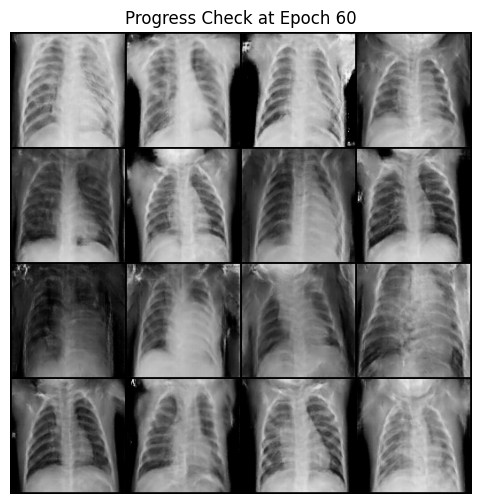

Epoch [61/75] Batch [0/82] Loss Critic: -4.2280 | Loss G (Adv): 56.1038 | Loss G (Feat): 0.8016
Epoch [62/75] Batch [0/82] Loss Critic: -4.8207 | Loss G (Adv): 57.5962 | Loss G (Feat): 0.8010
Epoch [63/75] Batch [0/82] Loss Critic: -4.3355 | Loss G (Adv): 58.8020 | Loss G (Feat): 0.7819
Epoch [64/75] Batch [0/82] Loss Critic: -4.4983 | Loss G (Adv): 58.4880 | Loss G (Feat): 0.8058
Epoch [65/75] Batch [0/82] Loss Critic: -4.4216 | Loss G (Adv): 61.7467 | Loss G (Feat): 0.7830
Epoch [66/75] Batch [0/82] Loss Critic: -4.8564 | Loss G (Adv): 64.9767 | Loss G (Feat): 0.8074
Epoch [67/75] Batch [0/82] Loss Critic: -4.2659 | Loss G (Adv): 64.3258 | Loss G (Feat): 0.8019
Epoch [68/75] Batch [0/82] Loss Critic: -3.8949 | Loss G (Adv): 65.9336 | Loss G (Feat): 0.7991
Epoch [69/75] Batch [0/82] Loss Critic: -4.4858 | Loss G (Adv): 66.0625 | Loss G (Feat): 0.7950
Epoch [70/75] Batch [0/82] Loss Critic: -4.5415 | Loss G (Adv): 66.5590 | Loss G (Feat): 0.7886
Epoch [71/75] Batch [0/82] Loss Critic: 

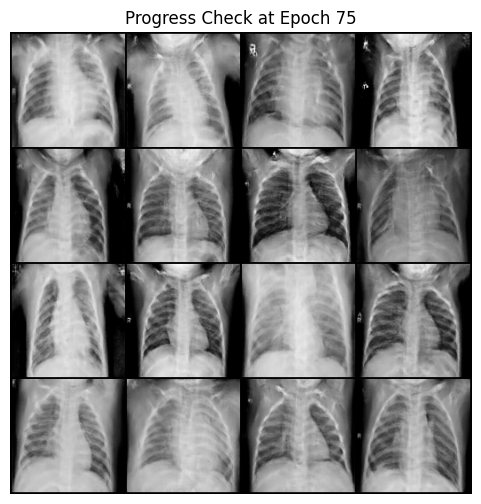

Full training curriculum completed successfully!


In [14]:
epochs = 75
save_interval = 15
lambda_gp = 10.0

print(f"Starting WGAN-GP training for {epochs} epochs...")

for epoch in range(epochs):
    netG.train()
    netC.train()

    for i, real_imgs in enumerate(dataloader):
        current_batch_size = real_imgs.size(0)
        real_imgs = real_imgs.to(device)

        # ---------------------
        #  Train Critic (n_critic times)
        # ---------------------
        for _ in range(n_critic):
            optimizerC.zero_grad()

            noise = torch.randn(current_batch_size, latent_dim, 1, 1, device=device)
            fake_imgs = netG(noise).detach()

            critic_real = netC(real_imgs)
            critic_fake = netC(fake_imgs)

            gp = compute_gradient_penalty(netC, real_imgs.data, fake_imgs.data, device)

            loss_critic = torch.mean(critic_fake) - torch.mean(critic_real) + lambda_gp * gp
            loss_critic.backward()
            optimizerC.step()

        # -----------------
        #  Train Generator
        # -----------------
        optimizerG.zero_grad()

        gen_noise = torch.randn(current_batch_size, latent_dim, 1, 1, device=device)
        gen_imgs = netG(gen_noise)

        loss_gen_adv = -torch.mean(netC(gen_imgs))

        real_features = feature_extractor(real_imgs).mean(dim=[2, 3])
        fake_features = feature_extractor(gen_imgs).mean(dim=[2, 3])
        loss_feature = torch.mean(torch.abs(real_features - fake_features))

        loss_gen = loss_gen_adv + 0.1 * loss_feature
        loss_gen.backward()
        optimizerG.step()

        if i % 100 == 0:
            print(f"Epoch [{epoch+1}/{epochs}] Batch [{i}/{len(dataloader)}] "
                  f"Loss Critic: {loss_critic.item():.4f} | Loss G (Adv): {loss_gen_adv.item():.4f} | Loss G (Feat): {loss_feature.item():.4f}")

    # ---------------------------------------------------------
    # Periodic Checkpoint & Visual Check every 15 epochs
    # ---------------------------------------------------------
    if (epoch + 1) % save_interval == 0 or (epoch + 1) == epochs:
        checkpoint_filename = f'grayscale_lung_wgan_epoch_{epoch+1}.pth'
        torch.save({
            'epoch': epoch + 1,
            'generator_state_dict': netG.state_dict(),
            'critic_state_dict': netC.state_dict(),
            'optimizerG_state_dict': optimizerG.state_dict(),
            'optimizerC_state_dict': optimizerC.state_dict(),
        }, checkpoint_filename)
        print(f"--> Checkpoint saved: {checkpoint_filename}")

        # Quick inline visualization to monitor training progression
        netG.eval()
        with torch.no_grad():
            sample_noise = torch.randn(16, latent_dim, 1, 1, device=device)
            progress_imgs = netG(sample_noise).detach().cpu()
            progress_imgs = (progress_imgs + 1) / 2.0

        plt.figure(figsize=(6, 6))
        grid_img = make_grid(progress_imgs, nrow=4, normalize=False)
        plt.axis("off")
        plt.title(f"Progress Check at Epoch {epoch+1}")
        plt.imshow(grid_img.permute(1, 2, 0).numpy(), cmap='gray')
        plt.show()

print("Full training curriculum completed successfully!")

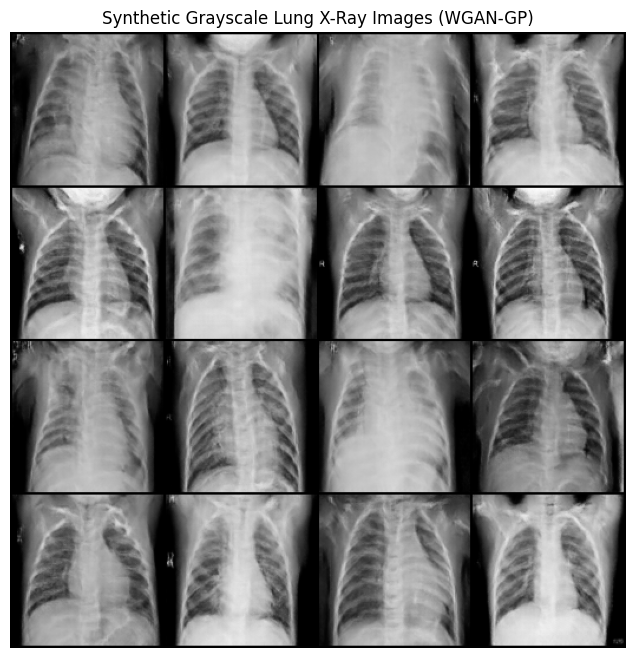

In [15]:
netG.eval()
num_images = 16

with torch.no_grad():
    sample_noise = torch.randn(num_images, latent_dim, 1, 1, device=device)
    generated_fake_imgs = netG(sample_noise).detach().cpu()
    # Unnormalize from [-1, 1] to [0, 1]
    generated_fake_imgs = (generated_fake_imgs + 1) / 2.0

plt.figure(figsize=(8, 8))
# Pass single channel explicitly with cmap='gray'
grid_img = make_grid(generated_fake_imgs, nrow=4, normalize=False)
plt.axis("off")
plt.title("Synthetic Grayscale Lung X-Ray Images (WGAN-GP)")
plt.imshow(grid_img.permute(1, 2, 0).numpy(), cmap='gray')
plt.show()